In [30]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import tifffile
import numpy as np
from scipy.optimize import curve_fit
from scipy.signal import savgol_filter
from scipy import stats
import pandas as pd
import matplotlib.transforms as mtransforms
from PIL import Image
from scipy.signal import savgol_filter

import cmcrameri.cm as cm
import analysis_functions as af

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
# load preshot images - alignment target
gated_alignment = []
gated_bg = []
gated_shot = []

for i in range(8):
    gated_alignment.append(tifffile.imread(f'data_shot3_raw/shadowgraphy/preshot/Alignment_target/Frame_{i+1}.tiff'))
for i in range(8):
    gated_bg.append(tifffile.imread(f'data_shot3_raw/shadowgraphy/preshot/No_alignment_target/Frame_{i+1}.tiff'))
for i in range(8):
    gated_shot.append(tifffile.imread(f'data_shot3_raw/shadowgraphy/shot/Frame_{i+1}.tiff'))

with Image.open('data_shot3_raw/streak/z4290leg1_laserstreak_preshot-nr.tif') as img:
    streak_pre_nr = np.array(img)
with Image.open('data_shot3_raw/streak/z4290leg1_laserstreak_preshot-r.tif') as img:
    streak_pre_r = np.array(img)   
with Image.open('data_shot3_raw/streak/z4290leg1_laserstreak.tif') as img:
    streak = np.array(img)

In [3]:
row_indices_cone = [1400, 1425, 1450, 1475, 1500, 1600, 1625, 1700, 1920, 1950, 2050]
middle = 1607
ranges = [200, 220, 225, 300, 300, 375, 400, 475, 700,700,700]
lower = []
higher = []

# x_bounds = (1200, 2000)
# y_bounds = (2000, 1300)

for i in range(len(row_indices_cone)):
    y_data = gated_alignment[5][row_indices_cone[i], :].astype(float)
    x_data = np.arange(len(y_data))
    width, start, end = af.calculate_object_edges(x_data, y_data, row_indices_cone[i], x_range=(middle - ranges[i], middle + ranges[i]), show_plot=False)
    higher.append(end)
    lower.append(start)

In [4]:
row_indices_cone = np.linspace(500, 2000, 30).astype(int)
middle = 750
width = 100
edges = []

# x_bounds = (1200, 2000)
# y_bounds = (2000, 1300)

for i in range(len(row_indices_cone)):
    y_data = gated_alignment[5][row_indices_cone[i], :].astype(float)
    x_data = np.arange(len(y_data))
    edge =  af.find_left_edge(x_data, y_data, row_indices_cone[i], x_range=(middle - width, middle + width), save_plot=False)
    edges.append(edge)

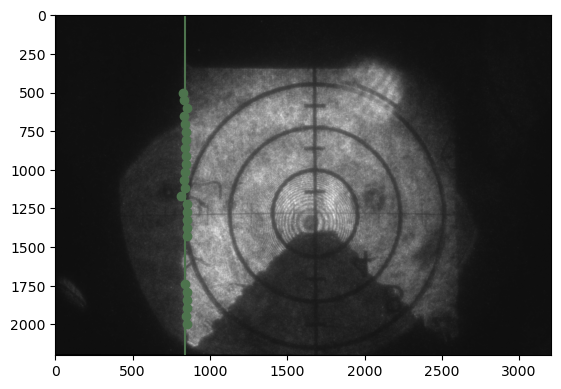

In [5]:
plt.imshow(gated_alignment[5], cmap = 'grey') 

edges = np.array(edges)
row_indices_cone = np.array(row_indices_cone)
edge_mask_1 = row_indices_cone < 1450
edge_mask_2 = row_indices_cone > 1699
edge_mask = edge_mask_1 | edge_mask_2

plt.scatter(edges[edge_mask], row_indices_cone[edge_mask], color = cm.batlowS(5))

left_edge = np.average(edges)
plt.axvline(left_edge, color = cm.batlowS(5))

# x_int = (intercept_right - intercept_left) / (slope_left - slope_right)
# y_int = slope_left * x_int + intercept_left
# plt.scatter(x_int, y_int, marker = 'x', s = 100, zorder = 2, color = 'tab:red', label = 'line intersection')

# plt.legend()
plt.show()

In [6]:
row_indices_cone = np.linspace(1000, 2000, 30).astype(int)
middle = 2600
width = 40
right_edges = []

# x_bounds = (1200, 2000)
# y_bounds = (2000, 1300)

for i in range(len(row_indices_cone)):
    y_data = gated_alignment[5][row_indices_cone[i], :].astype(float)
    x_data = np.arange(len(y_data))
    edge =  af.find_left_edge(x_data, y_data, row_indices_cone[i], x_range=(middle - width, middle + width), save_plot=True, object_type = 'bright')
    right_edges.append(edge)

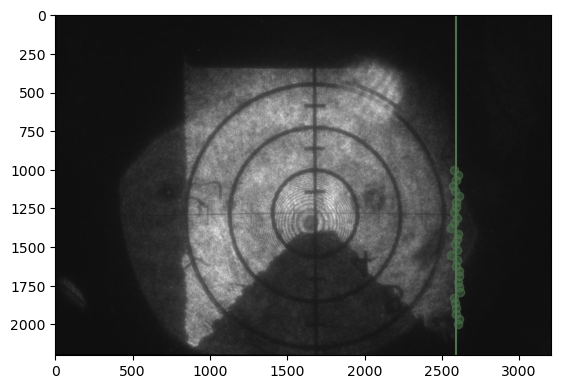

In [7]:
plt.imshow(gated_alignment[5], cmap = 'grey') 

right_edges = np.array(right_edges)
row_indices_cone = np.array(row_indices_cone)

plt.scatter(right_edges, row_indices_cone, color = cm.batlowS(5), alpha = 0.5)

right_edge = np.average(right_edges)
plt.axvline(right_edge, color = cm.batlowS(5))

# x_int = (intercept_right - intercept_left) / (slope_left - slope_right)
# y_int = slope_left * x_int + intercept_left
# plt.scatter(x_int, y_int, marker = 'x', s = 100, zorder = 2, color = 'tab:red', label = 'line intersection')

# plt.legend()
# plt.show()
plt.savefig('help')

In [8]:
col_indices = np.linspace(800, 1500, 30).astype(int)
middle = 315
width = 10
top_edges = []

for i in range(len(col_indices)):
    y_data = gated_alignment[5][:, col_indices[i]].astype(float)
    x_data = np.arange(len(y_data))
    edge =  af.find_top_edge(x_data, y_data, col_indices[i], y_range=(middle - width, middle + width), save_plot=False)
    top_edges.append(edge)

/home/timoney/.conda/envs/myenv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:1309: RuntimeWarning: divide by zero encountered in divide
  a = -(dx2) / (dx1 * (dx1 + dx2))
/home/timoney/.conda/envs/myenv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:1309: RuntimeWarning: invalid value encountered in divide
  a = -(dx2) / (dx1 * (dx1 + dx2))
/home/timoney/.conda/envs/myenv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:1310: RuntimeWarning: divide by zero encountered in divide
  b = (dx2 - dx1) / (dx1 * dx2)
/home/timoney/.conda/envs/myenv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:1310: RuntimeWarning: invalid value encountered in divide
  b = (dx2 - dx1) / (dx1 * dx2)
/home/timoney/.conda/envs/myenv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:1311: RuntimeWarning: divide by zero encountered in divide
  c = dx1 / (dx2 * (dx1 + dx2))
/home/timoney/.conda/envs/myenv/lib/python3.11/site-packages/numpy/lib/

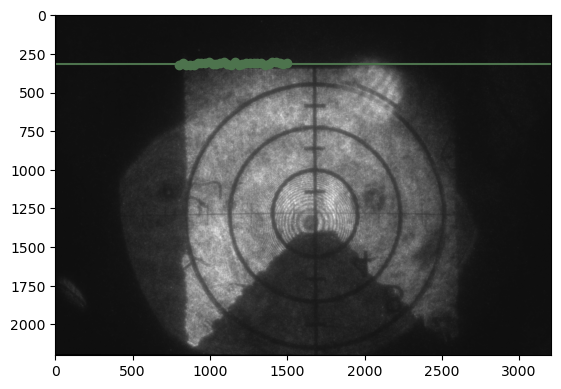

In [9]:
plt.imshow(gated_alignment[5], cmap = 'grey') 

top_edges = np.array(top_edges)
row_indices_cone = np.array(row_indices_cone)
# edge_mask_1 = row_indices_cone < 1450
# edge_mask_2 = row_indices_cone > 1699
# edge_mask = edge_mask_1 | edge_mask_2

plt.scatter(col_indices, top_edges, color = cm.batlowS(5))

top_edge = np.average(top_edges)
plt.axhline(top_edge, color = cm.batlowS(5))

# x_int = (intercept_right - intercept_left) / (slope_left - slope_right)
# y_int = slope_left * x_int + intercept_left
# plt.scatter(x_int, y_int, marker = 'x', s = 100, zorder = 2, color = 'tab:red', label = 'line intersection')

# plt.legend()
plt.show()

In [21]:
col_indices = np.linspace(1550, 1800, 30).astype(int)
middle = 1400
width = 10
cone_top = []

for i in range(len(col_indices)):
    y_data = gated_alignment[0][:, col_indices[i]].astype(float)
    x_data = np.arange(len(y_data))
    edge =  af.find_bottom_edge(x_data, y_data, col_indices[i], y_range=(middle - width, middle + width), save_plot=True)
    cone_top.append(edge)

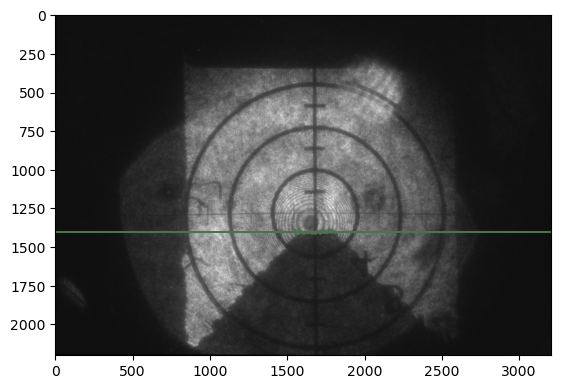

In [22]:
plt.imshow(gated_alignment[5], cmap = 'grey') 

cone_top = np.array(cone_top)
row_indices_cone = np.array(row_indices_cone)
# edge_mask_1 = row_indices_cone < 1450
# edge_mask_2 = row_indices_cone > 1699
# edge_mask = edge_mask_1 | edge_mask_2

plt.scatter(col_indices, cone_top, color = cm.batlowS(5), s = 1)

cone_top_row = np.average(cone_top)
plt.axhline(cone_top_row, color = cm.batlowS(5))

# x_int = (intercept_right - intercept_left) / (slope_left - slope_right)
# y_int = slope_left * x_int + intercept_left
# plt.scatter(x_int, y_int, marker = 'x', s = 100, zorder = 2, color = 'tab:red', label = 'line intersection')

# plt.legend()
plt.show()

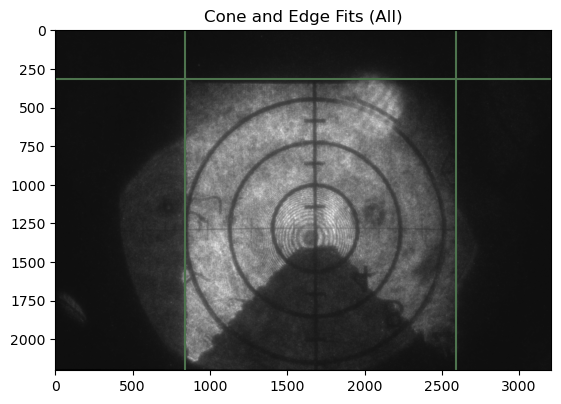

In [23]:
plt.imshow(gated_alignment[5], cmap = 'grey') 

plt.axvline(left_edge, color = cm.batlowS(5))
plt.axhline(top_edge, color = cm.batlowS(5))
plt.axvline(right_edge, color = cm.batlowS(5))

box_width_mm = 9.75
box_width_px = right_edge-left_edge

plt.title('Cone and Edge Fits (All)')
plt.savefig(f'sh_calib/cone/lines_all_f6', bbox_inches = 'tight')

179.9008547008547


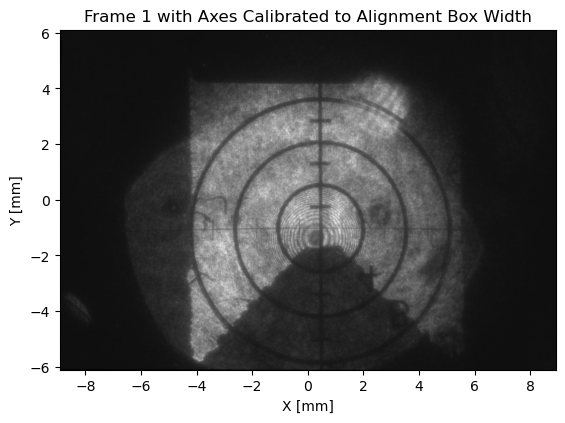

In [25]:
px_to_mm_box_width = box_width_mm/box_width_px

print(1/px_to_mm_box_width)

extent_x = gated_alignment[5].shape[1] * px_to_mm_box_width
extent_y = gated_alignment[5].shape[0] * px_to_mm_box_width
ext_box_w=[-extent_x/2, extent_x/2, -extent_y/2, extent_y/2]

fig, ax = plt.subplots()

plt.title('Frame 1 with Axes Calibrated to Alignment Box Width')
plt.imshow(gated_alignment[5], cmap = 'grey', extent=ext_box_w)

plt.xlabel('X [mm]')
plt.ylabel('Y [mm]')

plt.savefig(f'sh_calib/cone/calibrated_box_fr6', bbox_inches = 'tight')

In [24]:
# px_to_mm_cone = cone_width_mm/cone_width_px

# print(1/px_to_mm_cone)

# extent_x = gated_alignment[5].shape[1] * px_to_mm_cone
# extent_y = gated_alignment[5].shape[0] * px_to_mm_cone
# ext_cone=[-extent_x/2, extent_x/2, -extent_y/2, extent_y/2]

# fig, ax = plt.subplots()

# plt.title('Frame 1 with Axes Calibrated to Alignment Cone')
# plt.imshow(gated_alignment[5], cmap = 'grey', extent=ext_cone)

# plt.xlabel('X [mm]')
# plt.ylabel('Y [mm]')

# plt.savefig(f'sh_calib/cone/calibrated_cone_fr1', bbox_inches = 'tight')

In [26]:
# define image dimensions (2200, 3208)
image_width_pixels = 3208
image_height_pixels = 2200

# define x/y min/max from extent
x_min_mm, x_max_mm = -extent_x/2, extent_x/2
y_min_mm, y_max_mm = -extent_y/2, extent_y/2

# 2. Calibrating the reticle

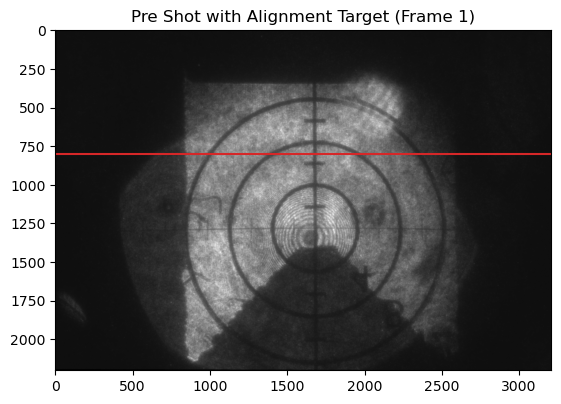

In [28]:
row_index = 800 # 1575

fig, ax = plt.subplots()

plt.title('Pre Shot with Alignment Target (Frame 1)')
plt.imshow(gated_alignment[5], cmap = 'grey')
plt.axhline(row_index, color = 'tab:red')

# plt.savefig(f'sh_calib/reticle/h_lineout_{row_index}_positions', bbox_inches = 'tight')

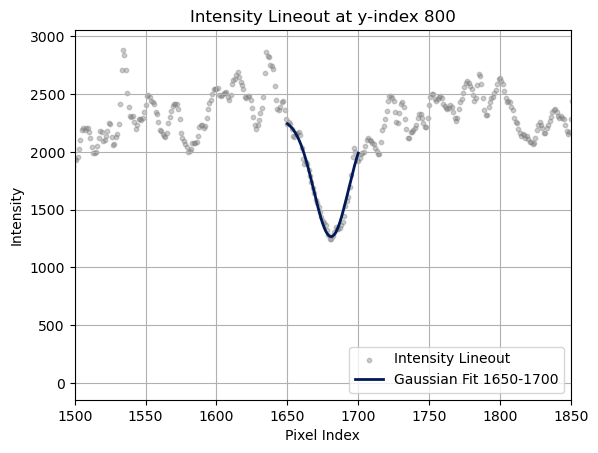

In [39]:
y_data = gated_alignment[5][row_index, :].astype(float)
x_data = np.arange(len(y_data))
plt.scatter(x_data, y_data, color='gray', alpha=0.4, label='Intensity Lineout', s=10)

min_brightness, min_position = af.get_min_brightness_gauss(x_data, y_data, start_index = 1650, end_index = 1700)

plt.title(f'Intensity Lineout at y-index {row_index}')
plt.xlim(1500,1850)
plt.xlabel('Pixel Index')
plt.ylabel('Intensity')
plt.legend(loc = 4)
plt.grid(True)
plt.savefig(f'sh_calib/reticle/h_lineout_{row_index}', bbox_inches = 'tight')

line index: 1681


<Figure size 640x480 with 0 Axes>

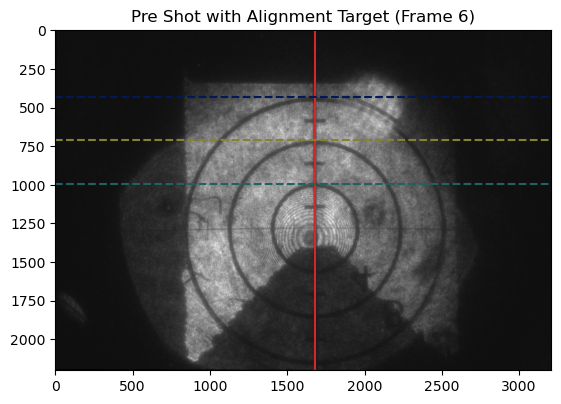

In [89]:
line_index = int(np.round(min_position, decimals = 0)) # 1575
print('line index:', line_index)

plt.scatter(x_data, y_data, color='gray', alpha=0.4, label='Intensity Lineout', s=10)

minimums_center = []
colors = [cm.batlowS(i) for i in range(8)]
colors = [colors[0], colors[2], colors[3],colors[5], colors[7]]

y_data = gated_alignment[0][:, line_index].astype(float)
x_data = np.arange(len(y_data))
plt.scatter(x_data, y_data, color='gray', alpha=0.4, label='Intensity Lineout', s=10)

min_b, min_p = af.get_min_brightness_gauss(x_data, y_data, start_index = 420, end_index = 450, plot = True)
minimums_center.append(min_p)

min_b, min_p = af.get_min_brightness_gauss(x_data, y_data, start_index = 690, end_index = 730)
minimums_center.append(min_p)

# min_b, min_p = af.get_min_brightness_gauss(x_data, y_data, start_index = 820, end_index = 880)
# minimums_center.append(min_p)

min_b, min_p = af.get_min_brightness_gauss(x_data, y_data, start_index = 975, end_index = 1015)
minimums_center.append(min_p)

# min_b, min_p = af.get_min_brightness_gauss(x_data, y_data, start_index = 1100, end_index = 1150)
# minimums_center.append(min_p)

for m in range(len(minimums_center)):
    plt.axvline(minimums_center[m], linestyle='--', color = colors[m])

plt.title(f'Intensity Lineout at x-index {line_index}')
plt.xlim(250,1500)
plt.xlabel('Pixel Index')
plt.ylabel('Intensity')
plt.legend(loc = 4)
plt.grid(True)
# plt.show()
plt.savefig(f'sh_calib/reticle/v_lineout_{line_index}_fr6', bbox_inches = 'tight')
plt.clf()

fig, ax = plt.subplots()

plt.title('Pre Shot with Alignment Target (Frame 6)')
plt.imshow(gated_alignment[5], cmap = 'grey')
plt.axvline(line_index, color = 'tab:red')

for m in range(len(minimums_center)):
    plt.axhline(minimums_center[m], linestyle='--', color = colors[m])

plt.savefig(f'sh_calib/reticle/v_lineout_{line_index}_positions_fr6', bbox_inches = 'tight')

In [85]:
spacings_mid = []
distances_mid = []
xcoords = []
ycoords = []
for i in range(len(minimums_center)):
    j = i+1
    while j < 3:
        dist = minimums_center[i]-minimums_center[j]
        distances_mid.append(-dist)
        spac = np.abs(dist/(2*(i-j)))
        spacings_mid.append(spac)
        xcoords.append(i)
        ycoords.append(j)
        j+=1

tab = {
    'x': xcoords,
    'y': ycoords,
    'distance': distances_mid,
    'spacing': spacings_mid
}

spac_table_mid = pd.DataFrame(tab)
spac_table_mid = spac_table_mid.round(2)

spac_table_mid.to_csv('sh_calib/reticle/spacings_fr6.csv', index=False)

In [86]:
pixel_positions_ret = minimums_center

# map to mm
# ret_positions_mm = np.interp(pixel_positions_ret, [0, image_width_pixels], [x_min_mm, x_max_mm])
ret_positions_mm = np.interp(pixel_positions_ret, [0, image_height_pixels], [y_max_mm, y_min_mm])
spacings_mm = np.average(spacings_mid)*px_to_mm_box_width

print("reticle spacing in pixels:", ret_positions_mm)
print("reticle spacing in mm:    ", np.round(ret_positions_mm, 3))
print('avg spacing in mm:        ', np.round(spacings_mm, 4))

reticle spacing in pixels: [3.72479988 2.16201411 0.59336201]
reticle spacing in mm:     [3.725 2.162 0.593]
avg spacing in mm:         0.7829


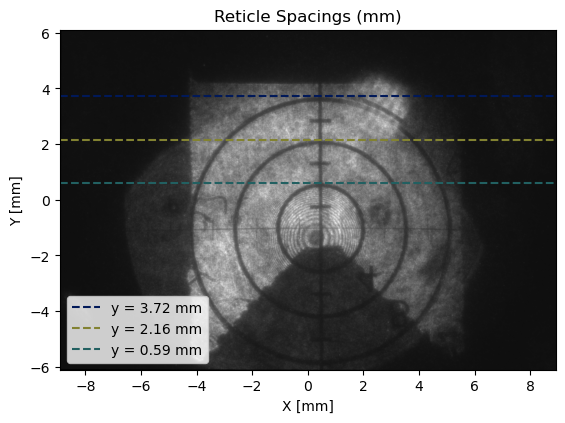

In [87]:
fig, ax = plt.subplots()

plt.imshow(gated_alignment[5], cmap = 'grey', extent=ext_box_w)
plt.title('Reticle Spacings (mm)')
plt.xlabel('X [mm]')
plt.ylabel('Y [mm]')

for m in range(len(ret_positions_mm)):
    plt.axhline(ret_positions_mm[m], linestyle='--', color = colors[m], label = f'y = {np.round(ret_positions_mm[m], 2)} mm')

plt.legend()
# plt.savefig(f'sh_calib/reticle/mm_v_linout_1607_positions.jpg', bbox_inches = 'tight')

# 3. Apply spacing to preshot streak ticks

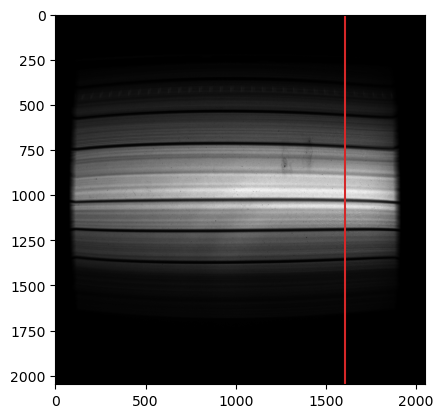

In [31]:
plt.imshow(streak_pre_r, cmap = 'gray')

line_index_sr = 1000

streak_rets = []
colors = [cm.batlowS(i) for i in range(8)]

y_data_sr = streak_pre_r[:, line_index_sr].astype(float)
x_data_sr = np.arange(len(y_data_sr))

plt.axvline(line_index, color = 'tab:red', label = 'lineout column')

Text(0.5, 1.0, 'Intensity lineout')

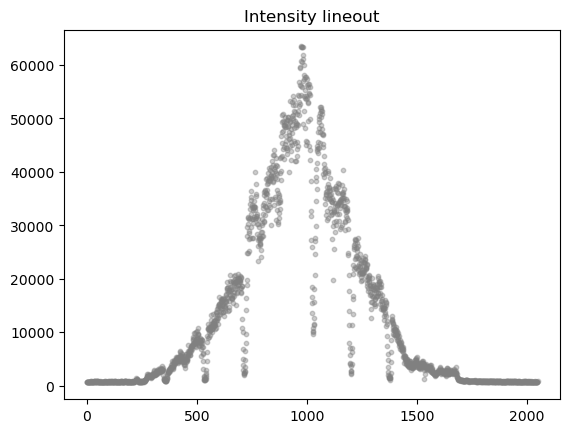

In [32]:
plt.scatter(x_data_sr, y_data_sr, color='gray', alpha=0.4, label='Intensity Lineout', s=10)
plt.title('Intensity lineout')

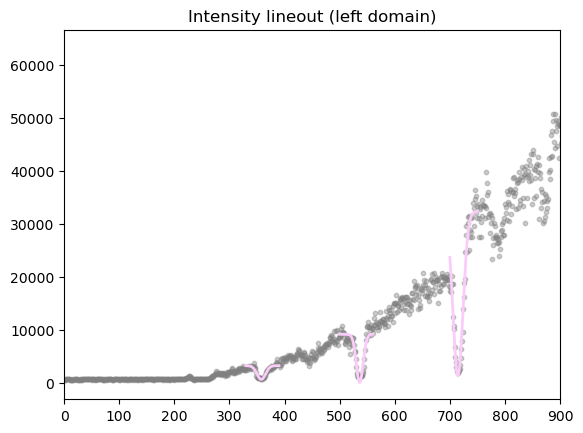

In [33]:
plt.scatter(x_data_sr, y_data_sr, color='gray', alpha=0.4, label='Intensity Lineout', s=10)
plt.title('Intensity lineout (left domain)')
plt.xlim(0, 900)

popt, cov, x_fit, y_fit = find_min_brightness(x_data_sr, y_data_sr, start_index = 330, end_index = 390)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 330-390', color = cm.batlowS(1))
curve_min = np.argmin(gaussian(x_detailed, *popt))
streak_rets.append(x_detailed[curve_min])

popt, cov, x_fit, y_fit = find_min_brightness(x_data_sr, y_data_sr, start_index = 500, end_index = 560)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 500-560', color = cm.batlowS(1))
curve_min = np.argmin(gaussian(x_detailed, *popt))
streak_rets.append(x_detailed[curve_min])

popt, cov, x_fit, y_fit = find_min_brightness(x_data_sr, y_data_sr, start_index = 700, end_index = 750)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 700-750', color = cm.batlowS(1))
curve_min = np.argmin(gaussian(x_detailed, *popt))
streak_rets.append(x_detailed[curve_min])

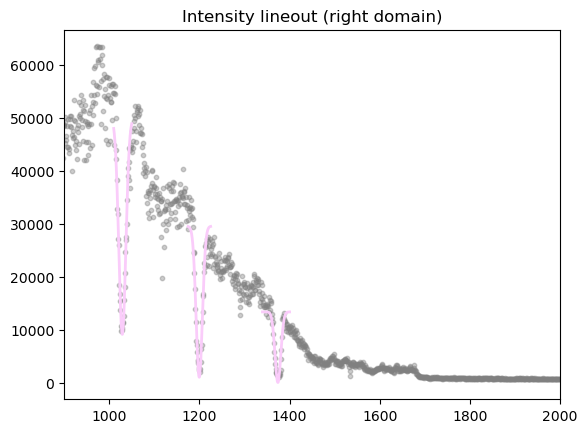

In [34]:
plt.scatter(x_data_sr, y_data_sr, color='gray', alpha=0.4, label='Intensity Lineout', s=10)
plt.title('Intensity lineout (right domain)')
plt.xlim(900, 2000)

popt, cov, x_fit, y_fit = find_min_brightness(x_data_sr, y_data_sr, start_index = 1010, end_index = 1050)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 330-390', color = cm.batlowS(1))
curve_min = np.argmin(gaussian(x_detailed, *popt))
streak_rets.append(x_detailed[curve_min])

popt, cov, x_fit, y_fit = find_min_brightness(x_data_sr, y_data_sr, start_index = 1175, end_index = 1225)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 500-560', color = cm.batlowS(1))
curve_min = np.argmin(gaussian(x_detailed, *popt))
streak_rets.append(x_detailed[curve_min])

popt, cov, x_fit, y_fit = find_min_brightness(x_data_sr, y_data_sr, start_index = 1340, end_index = 1400)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 700-750', color = cm.batlowS(1))
curve_min = np.argmin(gaussian(x_detailed, *popt))
streak_rets.append(x_detailed[curve_min])

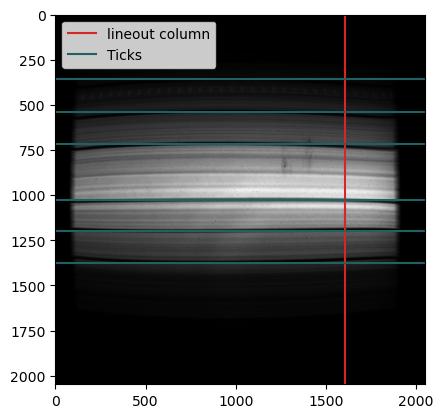

In [35]:
plt.imshow(streak_pre_r, cmap = 'gray')

line_index_sr = 1000

plt.axvline(line_index, color = 'tab:red', label = 'lineout column')

for r in range(len(streak_rets)):
    if r == 0:
        plt.axhline(streak_rets[r], label = f'Ticks', color = cm.batlowS(3))
    else:
        plt.axhline(streak_rets[r], color = cm.batlowS(3))

plt.legend()
# plt.savefig()

In [36]:
# avg spacing in mm : spacings_mm

spacings_sr = []
distances_sr = []
xcoords_sr = []
ycoords_sr = []
# print(len(streak_rets))
for i in range(3):
    j = i+1
    while j < 3:
        # if j < 2: 
        dist = streak_rets[i]-streak_rets[j]
        distances_sr.append(-dist)
        spac = np.abs(dist/(i-j))
        spacings_sr.append(spac)
        xcoords_sr.append(i)
        ycoords_sr.append(j)
        j+=1

for i in range(3):
    j = i+1
    while j < 3:
        # if j < 2: 
        dist = streak_rets[i+3]-streak_rets[j+3]
        distances_sr.append(-dist)
        spac = np.abs(dist/(i-j))
        spacings_sr.append(spac)
        xcoords_sr.append(i+3)
        ycoords_sr.append(j+3)
        j+=1

tab = {
    'x': xcoords_sr,
    'y': ycoords_sr,
    'distance': distances_sr,
    'spacing': spacings_sr
}

spac_tab_sr = pd.DataFrame(tab)
spac_tab_sr = spac_tab_sr.round(2)

avg_spacing_sr = np.average(spacings_sr)

print(avg_spacing_sr)

spac_tab_sr.to_csv('sh_calib/reticle/spacings_sr.csv', index=False)

175.4559118236473


In [37]:
px_to_mm_sr = (spacings_mm)/avg_spacing_sr

# TEMPORAL CALIBRATION: streak image

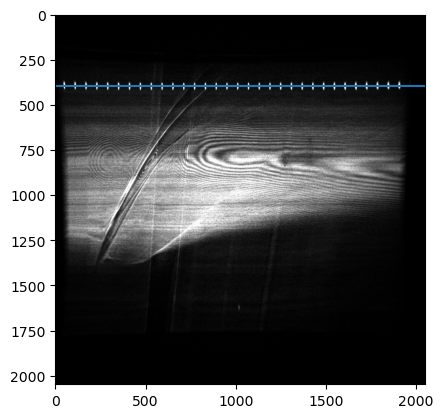

In [38]:
comb_index = 393
cmax = np.percentile(streak, 99)

plt.imshow(streak, cmap = 'gray')
plt.clim(0, cmax)
plt.axhline(comb_index)
plt.savefig(f'sh_calib/streak_timing/h_lineout_image', bbox_inches = 'tight')

12


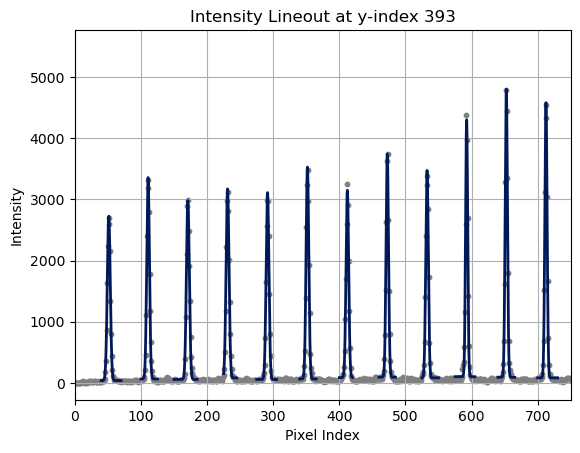

In [39]:
# calibrate time axes - 500 MHz comb frequency = one every 2 ns

ticks = []

y_comb = streak[comb_index, :].astype(float)
x_comb = np.arange(len(y_comb))

plt.scatter(x_comb, y_comb, color='gray', alpha=1, label='Intensity Lineout', s=10)

# calculate peaks
popt, cov, x_fit, y_fit = find_min_brightness(x_comb, y_comb, start_index = 40, end_index = 70)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 760-790', color = cm.batlowS(0))
ticks.append(x_detailed[np.argmax(gaussian(x_detailed, *popt))])

popt, cov, x_fit, y_fit = find_min_brightness(x_comb, y_comb, start_index = 100, end_index = 125)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 1180-1200', color = cm.batlowS(0))
ticks.append(x_detailed[np.argmax(gaussian(x_detailed, *popt))])

popt, cov, x_fit, y_fit = find_min_brightness(x_comb, y_comb, start_index = 150, end_index = 185)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 1180-1200', color = cm.batlowS(0))
ticks.append(x_detailed[np.argmax(gaussian(x_detailed, *popt))])

popt, cov, x_fit, y_fit = find_min_brightness(x_comb, y_comb, start_index = 225, end_index = 245)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 1180-1200', color = cm.batlowS(0))
ticks.append(x_detailed[np.argmax(gaussian(x_detailed, *popt))])

popt, cov, x_fit, y_fit = find_min_brightness(x_comb, y_comb, start_index = 275, end_index = 305)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 1180-1200', color = cm.batlowS(0))
ticks.append(x_detailed[np.argmax(gaussian(x_detailed, *popt))])

popt, cov, x_fit, y_fit = find_min_brightness(x_comb, y_comb, start_index = 340, end_index = 365)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 1180-1200', color = cm.batlowS(0))
ticks.append(x_detailed[np.argmax(gaussian(x_detailed, *popt))])

popt, cov, x_fit, y_fit = find_min_brightness(x_comb, y_comb, start_index = 400, end_index = 420)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 1180-1200', color = cm.batlowS(0))
ticks.append(x_detailed[np.argmax(gaussian(x_detailed, *popt))])

popt, cov, x_fit, y_fit = find_min_brightness(x_comb, y_comb, start_index = 460, end_index = 485)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 1180-1200', color = cm.batlowS(0))
ticks.append(x_detailed[np.argmax(gaussian(x_detailed, *popt))])

popt, cov, x_fit, y_fit = find_min_brightness(x_comb, y_comb, start_index = 525, end_index = 550)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 1180-1200', color = cm.batlowS(0))
ticks.append(x_detailed[np.argmax(gaussian(x_detailed, *popt))])

popt, cov, x_fit, y_fit = find_min_brightness(x_comb, y_comb, start_index = 575, end_index = 605)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 1180-1200', color = cm.batlowS(0))
ticks.append(x_detailed[np.argmax(gaussian(x_detailed, *popt))])

popt, cov, x_fit, y_fit = find_min_brightness(x_comb, y_comb, start_index = 640, end_index = 665)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 1180-1200', color = cm.batlowS(0))
ticks.append(x_detailed[np.argmax(gaussian(x_detailed, *popt))])

popt, cov, x_fit, y_fit = find_min_brightness(x_comb, y_comb, start_index = 700, end_index = 730)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 1180-1200', color = cm.batlowS(0))
ticks.append(x_detailed[np.argmax(gaussian(x_detailed, *popt))])

print(len(ticks))

plt.title(f'Intensity Lineout at y-index {comb_index}')
plt.xlim(0,750)
plt.xlabel('Pixel Index')
plt.ylabel('Intensity')
# plt.legend(loc = 4)
plt.grid(True)
plt.savefig(f'sh_calib/streak_timing/h_lineout_{row_index}_beg', bbox_inches = 'tight')

25


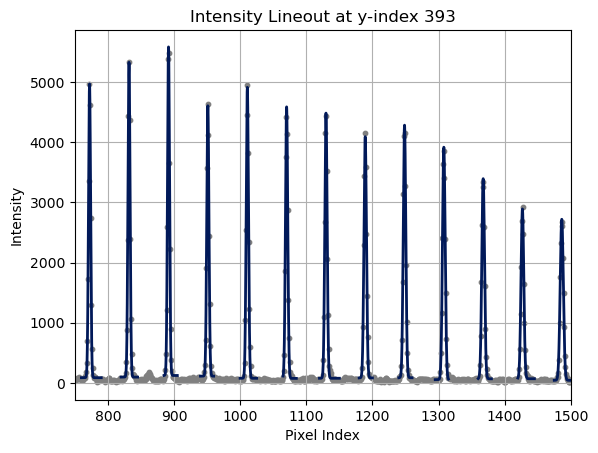

In [40]:
# calibrate time axes - 500 MHz comb frequency = one every 2 ns


plt.scatter(x_comb, y_comb, color='gray', alpha=1, label='Intensity Lineout', s=10)

popt, cov, x_fit, y_fit = find_min_brightness(x_comb, y_comb, start_index = 760, end_index = 790)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 760-790', color = cm.batlowS(0))
ticks.append(x_detailed[np.argmax(gaussian(x_detailed, *popt))])

popt, cov, x_fit, y_fit = find_min_brightness(x_comb, y_comb, start_index = 820, end_index = 845)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 820-845', color = cm.batlowS(0))
ticks.append(x_detailed[np.argmax(gaussian(x_detailed, *popt))])

popt, cov, x_fit, y_fit = find_min_brightness(x_comb, y_comb, start_index = 885, end_index = 905)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 885-905', color = cm.batlowS(0))
ticks.append(x_detailed[np.argmax(gaussian(x_detailed, *popt))])

popt, cov, x_fit, y_fit = find_min_brightness(x_comb, y_comb, start_index = 940, end_index = 960)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 940-960', color = cm.batlowS(0))
ticks.append(x_detailed[np.argmax(gaussian(x_detailed, *popt))])

popt, cov, x_fit, y_fit = find_min_brightness(x_comb, y_comb, start_index = 1000, end_index = 1025)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 1000-1025', color = cm.batlowS(0))
ticks.append(x_detailed[np.argmax(gaussian(x_detailed, *popt))])

popt, cov, x_fit, y_fit = find_min_brightness(x_comb, y_comb, start_index = 1065, end_index = 1085)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 1065-1085', color = cm.batlowS(0))
ticks.append(x_detailed[np.argmax(gaussian(x_detailed, *popt))])

popt, cov, x_fit, y_fit = find_min_brightness(x_comb, y_comb, start_index = 1120, end_index = 1150)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 1120-1150', color = cm.batlowS(0))
ticks.append(x_detailed[np.argmax(gaussian(x_detailed, *popt))])

popt, cov, x_fit, y_fit = find_min_brightness(x_comb, y_comb, start_index = 1180, end_index = 1200)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 1180-1200', color = cm.batlowS(0))
ticks.append(x_detailed[np.argmax(gaussian(x_detailed, *popt))])

popt, cov, x_fit, y_fit = find_min_brightness(x_comb, y_comb, start_index = 1240, end_index = 1260)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 1180-1200', color = cm.batlowS(0))
ticks.append(x_detailed[np.argmax(gaussian(x_detailed, *popt))])

popt, cov, x_fit, y_fit = find_min_brightness(x_comb, y_comb, start_index = 1295, end_index = 1315)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 1180-1200', color = cm.batlowS(0))
ticks.append(x_detailed[np.argmax(gaussian(x_detailed, *popt))])

popt, cov, x_fit, y_fit = find_min_brightness(x_comb, y_comb, start_index = 1360, end_index = 1380)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 1180-1200', color = cm.batlowS(0))
ticks.append(x_detailed[np.argmax(gaussian(x_detailed, *popt))])

popt, cov, x_fit, y_fit = find_min_brightness(x_comb, y_comb, start_index = 1420, end_index = 1445)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 1180-1200', color = cm.batlowS(0))
ticks.append(x_detailed[np.argmax(gaussian(x_detailed, *popt))])

popt, cov, x_fit, y_fit = find_min_brightness(x_comb, y_comb, start_index = 1475, end_index = 1500)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 1180-1200', color = cm.batlowS(0))
ticks.append(x_detailed[np.argmax(gaussian(x_detailed, *popt))])

print(len(ticks))

plt.title(f'Intensity Lineout at y-index {comb_index}')
plt.xlim(750,1500)
plt.xlabel('Pixel Index')
plt.ylabel('Intensity')
# plt.legend(loc = 4)
plt.grid(True)
plt.savefig(f'sh_calib/streak_timing/h_lineout_{row_index}_mid', bbox_inches = 'tight')

32


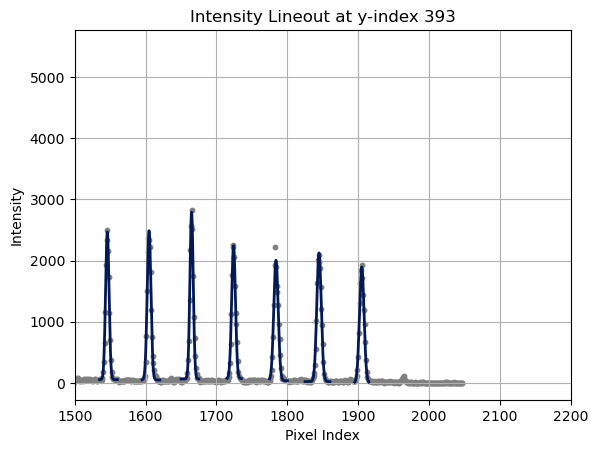

In [41]:
# calculate peaks
plt.scatter(x_comb, y_comb, color='gray', alpha=1, label='Intensity Lineout', s=10)

popt, cov, x_fit, y_fit = find_min_brightness(x_comb, y_comb, start_index = 1535, end_index = 1560)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 1180-1200', color = cm.batlowS(0))
ticks.append(x_detailed[np.argmax(gaussian(x_detailed, *popt))])

popt, cov, x_fit, y_fit = find_min_brightness(x_comb, y_comb, start_index = 1595, end_index = 1620)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 1180-1200', color = cm.batlowS(0))
ticks.append(x_detailed[np.argmax(gaussian(x_detailed, *popt))])

popt, cov, x_fit, y_fit = find_min_brightness(x_comb, y_comb, start_index = 1650, end_index = 1675)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 1180-1200', color = cm.batlowS(0))
ticks.append(x_detailed[np.argmax(gaussian(x_detailed, *popt))])

popt, cov, x_fit, y_fit = find_min_brightness(x_comb, y_comb, start_index = 1715, end_index = 1735)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 1180-1200', color = cm.batlowS(0))
ticks.append(x_detailed[np.argmax(gaussian(x_detailed, *popt))])

popt, cov, x_fit, y_fit = find_min_brightness(x_comb, y_comb, start_index = 1775, end_index = 1800)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 1180-1200', color = cm.batlowS(0))
ticks.append(x_detailed[np.argmax(gaussian(x_detailed, *popt))])

popt, cov, x_fit, y_fit = find_min_brightness(x_comb, y_comb, start_index = 1825, end_index = 1860)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 1180-1200', color = cm.batlowS(0))
ticks.append(x_detailed[np.argmax(gaussian(x_detailed, *popt))])

popt, cov, x_fit, y_fit = find_min_brightness(x_comb, y_comb, start_index = 1895, end_index = 1915)
x_detailed = np.linspace(x_fit.min(), x_fit.max(), 500)
plt.plot(x_detailed, gaussian(x_detailed, *popt), linewidth=2, label='Gaussian Fit 1180-1200', color = cm.batlowS(0))
ticks.append(x_detailed[np.argmax(gaussian(x_detailed, *popt))])

print(len(ticks))

plt.title(f'Intensity Lineout at y-index {comb_index}')
plt.xlim(1500,2200)
plt.xlabel('Pixel Index')
plt.ylabel('Intensity')
# plt.legend(loc = 4)
plt.grid(True)
plt.savefig(f'sh_calib/streak_timing/h_lineout_{row_index}_end', bbox_inches = 'tight')

In [42]:
spacings_ticks = []
distances_ticks = []
xcoords = []
ycoords = []
for i in range(len(ticks)):
    j = i+1
    while j < len(ticks):
        dist = ticks[i]-ticks[j]
        distances_ticks.append(-dist)
        spac = np.abs(dist/(i-j))
        spacings_ticks.append(spac)
        xcoords.append(i)
        ycoords.append(j)
        j+=1

tab = {
    'x': xcoords,
    'y': ycoords,
    'distance': distances_ticks,
    'spacing': spacings_ticks
}

spac_table_ticks = pd.DataFrame(tab)
spac_table_ticks = spac_table_ticks.round(2)

spac_table_ticks.to_csv('timings.csv', index=False)

print(spac_table_ticks)
print(np.average(spacings_ticks))

      x   y  distance  spacing
0     0   1     59.45    59.45
1     0   2    119.62    59.81
2     0   3    179.59    59.86
3     0   4    240.05    60.01
4     0   5    300.35    60.07
..   ..  ..       ...      ...
491  28  30    120.65    60.33
492  28  31    180.96    60.32
493  29  30     60.74    60.74
494  29  31    121.05    60.53
495  30  31     60.31    60.31

[496 rows x 4 columns]
59.7317255954399


In [43]:
time_step = np.average(spacings_ticks)

px_to_ns = 2/(time_step)
t0 = ticks[0] * px_to_ns

extent_x = streak.shape[1] * px_to_ns
extent_y = streak.shape[0] * px_to_ns # * px_to_mm
ext=[0, extent_x, -extent_y/2, extent_y/2]

In [44]:
px_to_mm_sr = (spacings_mm)/(avg_spacing_sr)

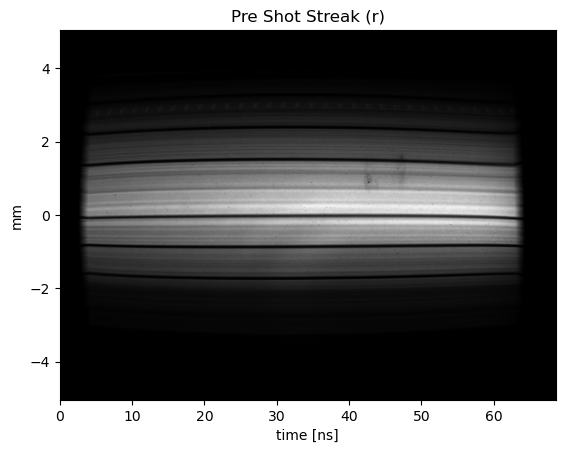

In [45]:
fig, ax = plt.subplots()

extent_x_sr = streak_pre_r.shape[1] * px_to_ns
extent_y_sr = streak_pre_r.shape[0] * px_to_mm_sr
ext_sr=[0, extent_x_sr, -extent_y_sr/2, extent_y_sr/2]

plt.imshow(streak_pre_r, cmap = 'grey', extent=ext_sr, aspect='auto')
plt.title('Pre Shot Streak (r)')
plt.xlabel('time [ns]')
plt.ylabel('mm')

plt.savefig(f'sh_calib/streak/corrected_pre_r.jpg', bbox_inches = 'tight')

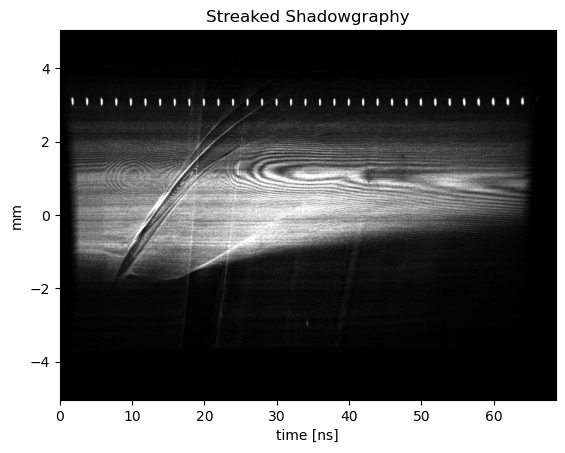

In [48]:
fig, ax = plt.subplots()

extent_x_sr = streak_pre_r.shape[1] * px_to_ns
extent_y_sr = streak_pre_r.shape[0] * px_to_mm_sr
ext_sr=[0, extent_x_sr, -extent_y_sr/2, extent_y_sr/2]

plt.imshow(streak, cmap = 'grey', extent=ext_sr, aspect='auto')

plt.title('Streaked Shadowgraphy')
plt.xlabel('time [ns]')
plt.ylabel('mm')

cmax = np.percentile(streak, 99)
plt.clim(0, cmax)

plt.savefig(f'sh_calib/streak/corrected_shot.jpg', bbox_inches = 'tight')

In [52]:
title = ['px_to_mm', 'px_to_ns']
values = [px_to_mm_sr, px_to_ns]

tab = {
    'type': title,
    'value': values,
}

output = pd.DataFrame(tab)

output.to_csv('streak_calib.csv', index=False)